# Question 3

In [42]:
import subprocess 

subprocess.run(["cyclus", "./closed_fuel_cycle.xml"])


              :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi                       
    CCC ;;         ;;  CC   ;;:                CCC`   `C;                     
  lCCC ;;              CCCC  ;;;:             :CC .;;. C;   ;    :   ;  :;;   
  CCCC ;.              CCCC    ;;;,           CC ;    ; Ci  ;    :   ;  :  ;  
   iCC :;               CC       ;;;,        ;C ;       CC  ;    :   ; .      
  CCCi ;;               CCC        ;;;.      .C ;   

Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental



Status: Cyclus run successful!
Output location: cyclus.sqlite
Simulation ID: 5e51d390-d35a-4ac7-a43c-b83ed0b701c0


CompletedProcess(args=['cyclus', './closed_fuel_cycle.xml'], returncode=0)

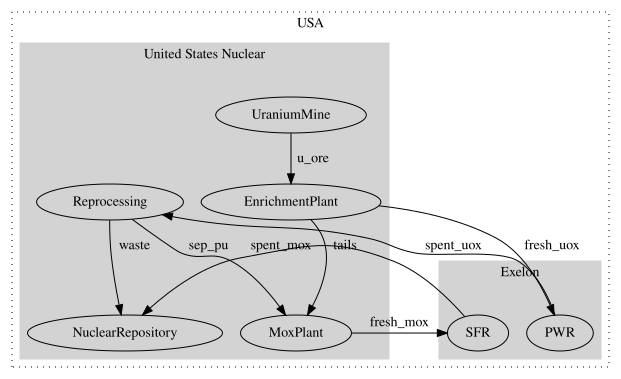

In [43]:
import cymetric as cym 
from cymetric import graphs as cgr
from cymetric import timeseries
import matplotlib.pyplot as plt


cdb = cym.dbopen("cyclus.sqlite")
ev = cym.Evaluator(db=cdb,write=False)


cgr.flow_graph(ev, label='comm')



**Part a)**

<Axes: >

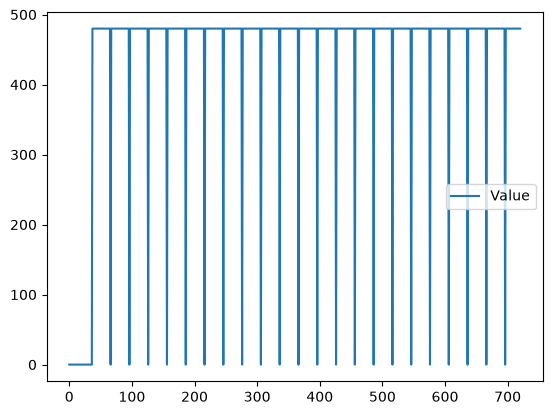

In [44]:
p = cym.timeseries.get_power(ev,facilities=["SFR"])
# power = ev.eval('TimeSeriesPower')
# sfr_power = power[power['AgentId'] == 21]
p.plot(y="Value")

# i) The SFR does not produce power until time step 37
# ii) In this simulation, there are no gaps in power, though in a
#       previous simulation, there appeared to be a gap in the middle
#       of the 60 year period... I can't seem to get it to come back

**Part b)**

In [47]:
# Fresh MOX required: 6.066 MTM
# Required Pu239 = (6066 kg) * 0.08
req_pu = 6066*0.08

# PWRs generate ~250 kg of Pu239 every cycle (lower enrichments, albeit)
# Num of Cycles  = (required Pu)/(250 kg/cycle)
# Num of Months = (Num of Cycles * (18 months/cycle)) + (3 months from institution "paths")
req_months = (req_pu/250)*18+3

# Close enough
print(f"Amount of months necessary to start SFR: {round(req_months,2)} Months") 

Amount of months necessary to start SFR: 37.94 Months


**Part c)**

In [ ]:
# Fresh MOX required: 1.011 MTM
# Required Pu239 = (1011 kg) * 0.08
req_pu = 1011*0.08

# PWRs generate ~250 kg of Pu239 every cycle (lower enrichments, albeit)
# Num of Cycles  = (required Pu)/(250 kg/cycle)
# Num of Months = (Num of Cycles * (18 months/cycle)) + (3 months from institution "paths")
req_months = (req_pu/250)*18+3

# Should technically be 18 months since we can't take the Pu239 out in the middle of a cycle
print(f"Amount of months necessary to reload SFR: {round(req_months,2)} Months") 

Amount of months necessary to reload SFR: 8.82 Months


**Part d)**

In [ ]:
# BU = (480 MWe)*(1/0.33 MWth/MWe) * (6 cycles)*(29 months/cycle)*(31 days/month) / (60.66 MTU)
bu = 480*(1/0.33)*(6*29*31)/60.66

# Like the previous questions, the real value is likely lower due to
#       the fact that higher burnup assemblies will contribute less to power,
#       depending on the fuel management being used
print(f"Batch-wise Average Discharge Burnup: {round(bu,2)}")

Batch-wise Average Discharge Burnup: 129340.89


Part e)

In [ ]:
# Similar to previous questions, recycling Pu from the PWR would allow for 
#       a lower reload-required amount of Pu239. Time delays for cooling would
#       presumably just increase the time for reloads. Any operating company would
#       want to increase the power density to make up for lost profits, however...

**Part f)**

In [ ]:
# Increasing power density would presumably decrease the amount of heavy
#       metal required for a reload. For a startup however, there would
#       be no effect if the same total amount of heavy metal is still used.

**Part g)**

In [51]:
# Gas-cooled fast reactors would presumably have a low power density,
#   based off of the other gas reactors referenced in this class...